In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

events = pd.read_csv('data/events.csv')
listings = pd.read_csv('data/listings.csv')
messages = pd.read_csv('data/messages.csv')
surveys = pd.read_csv('data/surveys.csv')
verified = pd.read_csv('data/verified.csv')

verified_0 = verified[verified['is_deal'] == 0]
verified_1 = verified[verified['is_deal'] == 1]

verified_0, verified_1

(     listing_id  is_deal
 0        100681        0
 1        101419        0
 2        101514        0
 3        101847        0
 4        101907        0
 ..          ...      ...
 292      160017        0
 294      160585        0
 296      160740        0
 297      161072        0
 299      161231        0
 
 [184 rows x 2 columns],
      listing_id  is_deal
 5        102003        1
 6        102331        1
 9        102885        1
 10       103007        1
 11       103373        1
 ..          ...      ...
 282      158309        1
 288      159086        1
 293      160166        1
 295      160714        1
 298      161213        1
 
 [116 rows x 2 columns])

In [2]:
verified_listings_0 = listings[listings['listing_id'].isin(verified_0['listing_id'])].drop_duplicates(subset=['listing_id'])
verified_listings_1 = listings[listings['listing_id'].isin(verified_1['listing_id'])].drop_duplicates(subset=['listing_id'])

verified_listings_0

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
96,152219,38883,private,Спорт и отдых,Коньки отличное состояние,5260,5260,2,45.0,Краснодар,2026-09-27 18:03:35,2026-10-03 13:31:14,снято продавцом,36,0,0,3,6
162,133335,26727,private,Бытовая техника,Мультиварка торг,19120,19120,4,61.0,Москва,2026-09-09 08:22:14,2026-09-14 12:56:15,снято продавцом,60,3,0,1,13
242,115714,22840,private,Мебель и интерьер,Люстра,9300,7550,4,129.0,Москва,2026-08-19 21:24:55,2026-09-18 21:24:55,истёк срок,278,7,3,11,42
287,159583,19213,private,Электроника,Игровая приставка,14770,14770,2,NaN,Екатеринбург,2026-10-04 17:49:59,2026-10-18 20:38:31,снято продавцом,146,6,2,4,13
294,109228,18276,private,Детские товары,Комбинезон зимний,5250,3980,3,176.0,Москва,2026-08-12 15:53:29,2026-09-11 15:53:29,истёк срок,169,4,2,13,35
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15125,114464,12962,private,Электроника,iPhone 12 128 ГБ б/у,14470,14470,5,122.0,Краснодар,2026-08-18 15:28:05,2026-09-17 15:28:05,истёк срок,294,12,3,14,53
15148,125458,20955,private,Мебель и интерьер,Люстра,4110,4110,3,50.0,Москва,2026-08-31 20:19:52,2026-09-09 13:56:03,снято продавцом,53,2,0,2,5
15161,122935,21280,private,Одежда и обувь,Свитер вязаный в хорошем состоянии,2170,2170,4,100.0,Краснодар,2026-08-28 20:29:54,2026-08-31 12:09:28,снято продавцом,23,0,0,2,4
15187,122765,25599,private,Одежда и обувь,Платье вечернее,1270,1270,4,33.0,Москва,2026-08-28 18:09:45,2026-09-09 18:41:33,снято продавцом,55,1,1,4,7


In [3]:
verified_listings_1

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
772,159086,15663,private,Одежда и обувь,Сапоги зимние в хорошем состоянии,1080,1080,5,151.0,Екатеринбург,2026-10-04 11:02:17,2026-10-09 16:15:23,снято продавцом,76,2,0,4,20
787,103547,11596,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,990,990,7,28.0,Санкт Петербург,2026-08-05 16:12:26,2026-08-11 14:34:59,снято продавцом,178,6,2,8,40
987,150404,13076,private,Детские товары,Манеж,870,870,4,102.0,Москва,2026-09-25 20:23:43,2026-10-04 13:47:14,снято продавцом,38,1,2,1,11
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14619,144561,36488,private,Электроника,Колонка JBL,18130,18130,4,148.0,Новосибирск,2026-09-19 22:43:06,2026-09-28 16:49:37,снято продавцом,85,3,0,2,12
14708,148845,35763,private,Запчасти и аксессуары,Фара передняя новый,3460,3460,4,117.0,Москва,2026-09-24 13:34:55,2026-10-24 13:34:55,истёк срок,196,7,8,2,12
15121,103373,13326,private,Мебель и интерьер,Ковёр 2x3 как новый,7320,7320,2,194.0,казань,2026-08-05 12:01:09,2026-08-12 18:57:33,снято продавцом,31,0,0,3,18
15128,110353,19047,private,Бытовая техника,Микроволновка,17660,17660,6,63.0,Казань,2026-08-13 19:52:40,2026-08-20 12:02:28,снято продавцом,90,4,0,3,15


## Анализ is_deal == 1

In [4]:
df = verified_listings_1.copy()

# Очевидно что listing_id, seller_id не влияют, так что смотрим дальше
df_private = df[df['seller_type'] == 'private']
df_business = df[df['seller_type'] == 'business']

df_private

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
772,159086,15663,private,Одежда и обувь,Сапоги зимние в хорошем состоянии,1080,1080,5,151.0,Екатеринбург,2026-10-04 11:02:17,2026-10-09 16:15:23,снято продавцом,76,2,0,4,20
787,103547,11596,private,Одежда и обувь,Куртка зимняя в хорошем состоянии,990,990,7,28.0,Санкт Петербург,2026-08-05 16:12:26,2026-08-11 14:34:59,снято продавцом,178,6,2,8,40
987,150404,13076,private,Детские товары,Манеж,870,870,4,102.0,Москва,2026-09-25 20:23:43,2026-10-04 13:47:14,снято продавцом,38,1,2,1,11
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14619,144561,36488,private,Электроника,Колонка JBL,18130,18130,4,148.0,Новосибирск,2026-09-19 22:43:06,2026-09-28 16:49:37,снято продавцом,85,3,0,2,12
14708,148845,35763,private,Запчасти и аксессуары,Фара передняя новый,3460,3460,4,117.0,Москва,2026-09-24 13:34:55,2026-10-24 13:34:55,истёк срок,196,7,8,2,12
15121,103373,13326,private,Мебель и интерьер,Ковёр 2x3 как новый,7320,7320,2,194.0,казань,2026-08-05 12:01:09,2026-08-12 18:57:33,снято продавцом,31,0,0,3,18
15128,110353,19047,private,Бытовая техника,Микроволновка,17660,17660,6,63.0,Казань,2026-08-13 19:52:40,2026-08-20 12:02:28,снято продавцом,90,4,0,3,15


In [5]:
df_business

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
2044,154766,15252,business,Детские товары,Радионяня б/у,1590,1210,10,146.0,Санкт-Петербург,2026-09-30 11:20:21,2026-10-30 11:20:21,истёк срок,655,14,3,29,118
2181,112494,15720,business,Детские товары,Кроватка детская как новый,3880,3880,6,92.0,Санкт-Петербург,2026-08-16 10:26:08,2026-09-15 10:26:08,истёк срок,101,3,0,9,34
2264,138670,11709,business,Запчасти и аксессуары,Зеркало боковое как новый,1430,1430,7,57.0,Санкт-Петербург,2026-09-14 11:43:20,2026-10-14 11:43:20,истёк срок,246,8,12,9,43
2626,112537,20669,business,Детские товары,Санки-коляска б/у,4400,4400,10,108.0,Нижний Новгород,2026-08-16 11:44:32,2026-09-15 11:44:32,истёк срок,833,31,6,28,116
2781,119235,10756,business,Одежда и обувь,Платье вечернее срочно,3890,3260,6,543.0,Казань,2026-08-24 11:07:21,2026-09-23 11:07:21,истёк срок,187,5,2,10,37
4088,111129,10499,business,Электроника,Смартфон Xiaomi Redmi Note 11,14450,13580,4,59.0,краснодар,2026-08-14 17:48:41,2026-09-13 17:48:41,истёк срок,243,9,3,15,54
4371,129127,11774,business,Запчасти и аксессуары,Шины зимние R16 с документами,5690,5690,6,426.0,Самара,2026-09-04 19:04:06,2026-10-04 19:04:06,истёк срок,249,7,7,6,18
5740,157028,11709,business,Запчасти и аксессуары,Видеорегистратор б/у,2630,2630,7,882.0,Санкт-Петербург,2026-10-02 11:28:21,2026-11-01 11:28:21,истёк срок,264,7,7,9,32
7519,131725,21227,business,Детские товары,Конструктор LEGO,1270,960,7,797.0,Москва,2026-09-07 15:05:41,2026-10-07 15:05:41,истёк срок,333,11,5,20,111
9440,142142,14841,business,Детские товары,Автокресло срочно,5440,4490,7,NaN,Нижний Новгород,2026-09-17 16:27:59,2026-10-17 16:27:59,истёк срок,194,10,2,10,36


In [6]:
len(df_private), len(df_business)

(99, 17)

In [7]:
df_categories = df['category'].value_counts()
df_categories

category
Электроника              30
Детские товары           21
Одежда и обувь           17
Мебель и интерьер        16
Бытовая техника          12
Запчасти и аксессуары    10
Спорт и отдых             7
Name: count, dtype: int64

In [8]:
df_sorted_prices = df.sort_values(by='price', ascending=False)
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
3003,154610,27924,private,Мебель и интерьер,Диван угловой с документами,99999999,99999999,5,62.0,Краснодар,2026-09-29 23:10:18,2026-10-07 21:01:04,снято продавцом,150,2,3,7,25
11868,110865,13634,business,NaN,Ноутбук Lenovo IdeaPad как новый,57480,57480,10,328.0,Екатеринбург,2026-08-14 12:06:41,2026-09-13 12:06:41,истёк срок,277,8,4,15,74
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
7285,112124,20365,private,Электроника,Роутер Wi-Fi как новый,24720,24720,4,NaN,Москва,2026-08-15 19:15:53,2026-08-20 13:33:13,снято продавцом,39,2,0,1,15
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9593,115027,22399,private,Детские товары,Коляска 2 в 1,620,620,3,131.0,Москва,2026-08-18 23:32:03,2026-08-23 09:00:48,снято продавцом,80,3,1,2,17
1311,148166,12710,private,Одежда и обувь,Пуховик женский новый,610,610,4,27.0,Санкт-Петербург,2026-09-23 18:38:54,2026-10-23 18:38:54,истёк срок,299,12,2,15,66
12477,131019,17823,business,Одежда и обувь,Свитер вязаный,550,430,4,408.0,Казань,2026-09-06 19:09:12,2026-10-06 19:09:12,истёк срок,291,9,3,15,50
10544,161213,24488,business,Одежда и обувь,Рюкзак городской,490,490,7,140.0,Казань,2026-10-05 23:03:44,2026-11-04 23:03:44,истёк срок,545,18,3,31,98


Ответ экспертов:
Массив verified нужно использовать как источник подтверждённых сделок, но это не означает, что каждое наблюдение обязательно нужно включать в анализ без дополнительной обработки.

В реальных данных такие значения могут появляться по разным причинам.

Вам нужно самостоятельно решить, как поступить с таким примером: оставить его, исключить или использовать устойчивые к выбросам методы. Главное - объяснить и обосновать выбранный подход в решении.

Считаем что диван - выброс, так что его убираем из дата сета

In [9]:
df_sorted_prices = df_sorted_prices.drop(index=df_sorted_prices.index[0])
df_sorted_prices

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
11868,110865,13634,business,NaN,Ноутбук Lenovo IdeaPad как новый,57480,57480,10,328.0,Екатеринбург,2026-08-14 12:06:41,2026-09-13 12:06:41,истёк срок,277,8,4,15,74
664,143034,14480,private,Электроника,Смартфон Xiaomi Redmi Note 11,53300,53300,9,NaN,Новосибирск,2026-09-18 14:19:51,2026-09-27 23:38:12,снято продавцом,146,2,3,8,20
7285,112124,20365,private,Электроника,Роутер Wi-Fi как новый,24720,24720,4,NaN,Москва,2026-08-15 19:15:53,2026-08-20 13:33:13,снято продавцом,39,2,0,1,15
1071,128623,14037,private,Электроника,Колонка JBL с документами,22410,22410,5,314.0,Самара,2026-09-04 12:04:36,2026-09-07 12:51:10,снято продавцом,108,6,1,1,4
7620,122888,27500,private,Мебель и интерьер,Стеллаж срочно,22140,22140,9,92.0,Санкт-Петербург,2026-08-28 19:52:50,2026-09-02 09:09:01,снято продавцом,70,2,1,2,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9593,115027,22399,private,Детские товары,Коляска 2 в 1,620,620,3,131.0,Москва,2026-08-18 23:32:03,2026-08-23 09:00:48,снято продавцом,80,3,1,2,17
1311,148166,12710,private,Одежда и обувь,Пуховик женский новый,610,610,4,27.0,Санкт-Петербург,2026-09-23 18:38:54,2026-10-23 18:38:54,истёк срок,299,12,2,15,66
12477,131019,17823,business,Одежда и обувь,Свитер вязаный,550,430,4,408.0,Казань,2026-09-06 19:09:12,2026-10-06 19:09:12,истёк срок,291,9,3,15,50
10544,161213,24488,business,Одежда и обувь,Рюкзак городской,490,490,7,140.0,Казань,2026-10-05 23:03:44,2026-11-04 23:03:44,истёк срок,545,18,3,31,98


In [10]:
df_chaged_price = df[df['price'] != df['current_price']]
df_chaged_price

,listing_id,seller_id,seller_type,category,title,price,current_price,photos_count,description_length,region,published_at,closed_at,close_type,views_total,favorites_total,phone_views_total,chats_total,messages_total
1655,128675,30396,private,Детские товары,Манеж отличное состояние,1020,810,2,136.0,Санкт-Петербург,2026-09-04 12:59:31,2026-09-14 09:26:46,снято продавцом,87,1,1,4,16
1757,131634,31763,private,Бытовая техника,Мультиварка торг,7540,6560,6,50.0,Самара,2026-09-07 13:20:05,2026-09-12 08:55:57,снято продавцом,40,1,0,3,26
2044,154766,15252,business,Детские товары,Радионяня б/у,1590,1210,10,146.0,Санкт-Петербург,2026-09-30 11:20:21,2026-10-30 11:20:21,истёк срок,655,14,3,29,118
2562,140801,35212,private,Мебель и интерьер,Стеллаж с документами,1760,1510,3,138.0,самара,2026-09-16 12:30:36,2026-10-04 10:45:26,снято продавцом,172,5,4,7,22
2781,119235,10756,business,Одежда и обувь,Платье вечернее срочно,3890,3260,6,543.0,Казань,2026-08-24 11:07:21,2026-09-23 11:07:21,истёк срок,187,5,2,10,37
3278,142739,35831,private,Электроника,Наушники беспроводные б/у,12150,10080,2,21.0,Санкт-Петербург,2026-09-18 08:24:58,2026-09-21 09:44:29,снято продавцом,45,1,0,3,7
3296,125035,20931,private,Бытовая техника,Кофемашина DeLonghi новый,14020,10990,2,166.0,Санкт-Петербург,2026-08-31 15:22:27,2026-09-05 09:22:04,снято продавцом,20,0,1,1,15
3631,154049,10382,private,Электроника,Смартфон Xiaomi Redmi Note 11 в хорошем состоянии,17720,15140,1,57.0,Нижний Новгород,2026-09-29 16:15:45,2026-10-04 11:02:19,снято продавцом,58,1,0,4,21
3912,144084,36306,private,Бытовая техника,Стиральная машина LG,5390,4300,1,48.0,Москва,2026-09-19 16:06:06,2026-10-05 16:00:40,снято продавцом,102,3,1,4,19
4088,111129,10499,business,Электроника,Смартфон Xiaomi Redmi Note 11,14450,13580,4,59.0,краснодар,2026-08-14 17:48:41,2026-09-13 17:48:41,истёк срок,243,9,3,15,54


In [11]:
len(df_chaged_price)

27

In [12]:
df_photos_count = df['photos_count'].value_counts().sort_index()
df_photos_count

photos_count
0      4
1      5
2     13
3     16
4     21
5     16
6     19
7     12
8      3
9      3
10     4
Name: count, dtype: int64

Забавно, что нормальное распределение по кол-ву фотографий. Но не 100% показатель

In [13]:
df_description_length = df['description_length'].value_counts().sort_index()
df_description_length

description_length
18.0     1
21.0     1
27.0     1
28.0     1
44.0     1
        ..
484.0    1
543.0    1
629.0    1
797.0    1
882.0    1
Name: count, Length: 87, dtype: int64

In [14]:
df_delta_time = pd.to_timedelta(df['closed_at'].apply(lambda x: pd.to_datetime(x).timestamp()) - df['published_at'].apply(lambda x: pd.to_datetime(x).timestamp()), unit='s')
df_delta_time = df_delta_time.value_counts().sort_index()
df_delta_time

-7 days +08:04:58     1
0 days 19:32:50       1
1 days 02:31:49       1
1 days 14:18:57       1
1 days 15:33:59       1
                     ..
17 days 22:14:50      1
19 days 00:43:11      1
22 days 22:06:57      1
26 days 17:13:42      1
30 days 00:00:00     27
Name: count, Length: 90, dtype: int64

Нужно дописать проверку относительно времени выставления и закрытия обьявления \
30 дней - смерть обьявления

In [15]:
df_close_type = df['close_type'].value_counts()
df_close_type

close_type
снято продавцом    89
истёк срок         27
Name: count, dtype: int64

Следует обращать внимание на обьявления которые снялись площадкой по истечения срока, тк продавец мог просто забыть снять обьявление, даже после продажи товара

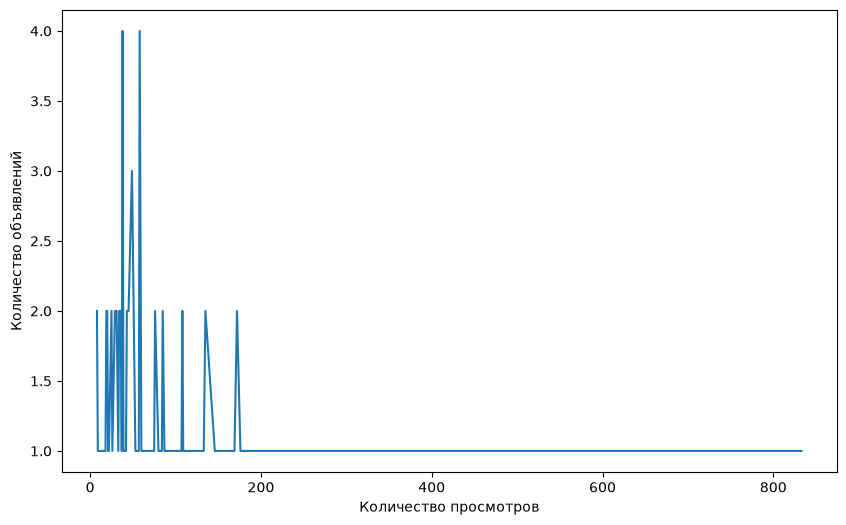

In [16]:
df_views_total = df['views_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_views_total.index, df_views_total.values)
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.show()

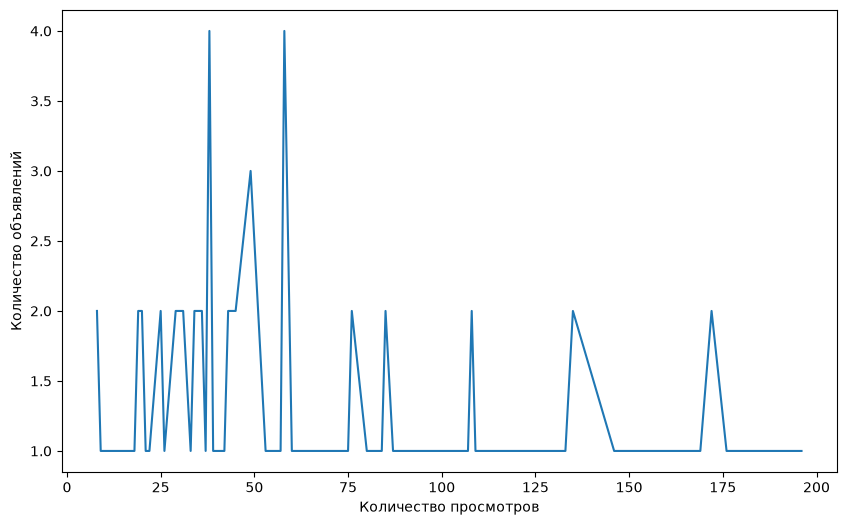

In [17]:
df_views_total_tmp = df_views_total[df_views_total.index < 200]
plt.figure(figsize=(10, 6))
plt.xlabel('Количество просмотров')
plt.ylabel('Количество объявлений')
plt.plot(df_views_total_tmp.index, df_views_total_tmp.values)
plt.show()

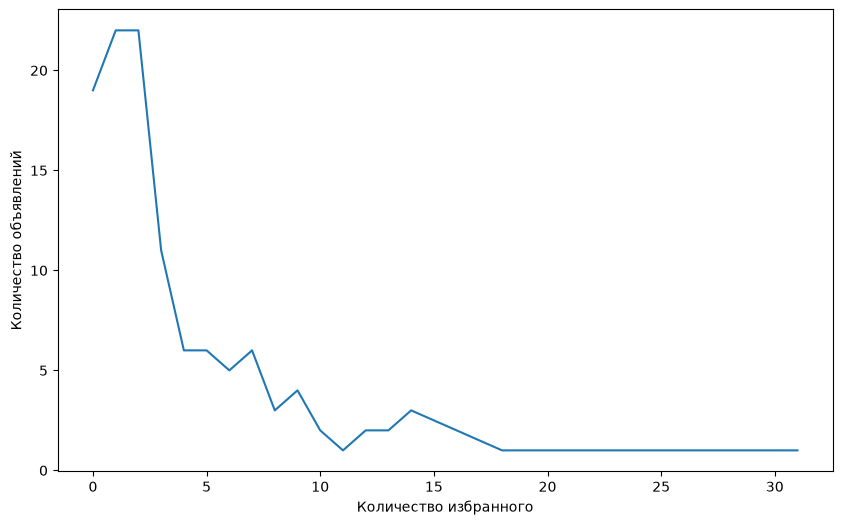

In [18]:
df_favorites_total = df['favorites_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_favorites_total.index, df_favorites_total.values)
plt.xlabel('Количество избранного')
plt.ylabel('Количество объявлений')
plt.show()

phone_views_total
0     47
1     28
2     20
3      9
4      5
5      2
6      1
7      2
8      1
12     1
Name: count, dtype: int64

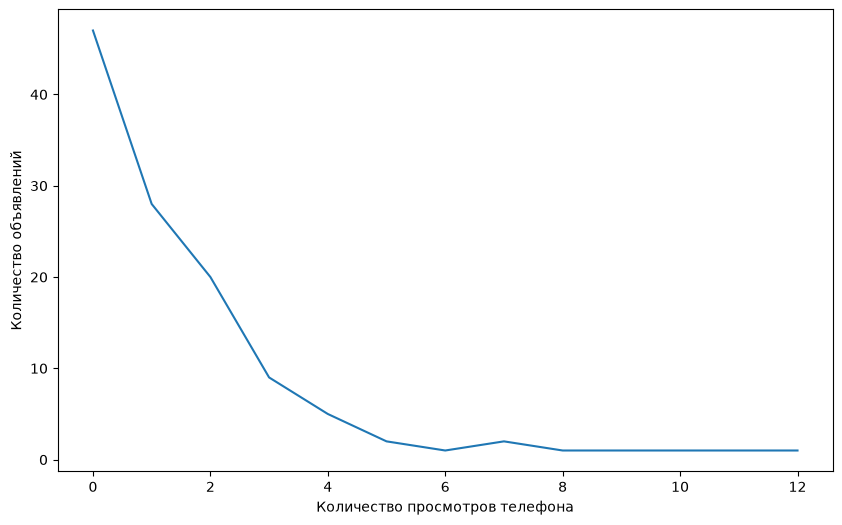

In [19]:
df_phone_views_total = df['phone_views_total'].value_counts().sort_index()
display(df_phone_views_total)
plt.figure(figsize=(10, 6))
plt.plot(df_phone_views_total.index, df_phone_views_total.values)
plt.xlabel('Количество просмотров телефона')
plt.ylabel('Количество объявлений')
plt.show()

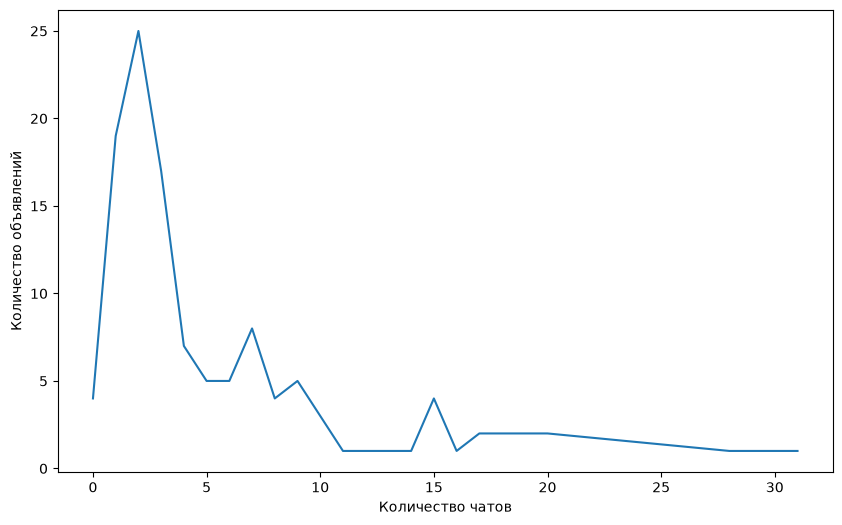

In [20]:
df_chats_total = df['chats_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_chats_total.index, df_chats_total.values)
plt.xlabel('Количество чатов')
plt.ylabel('Количество объявлений')
plt.show()

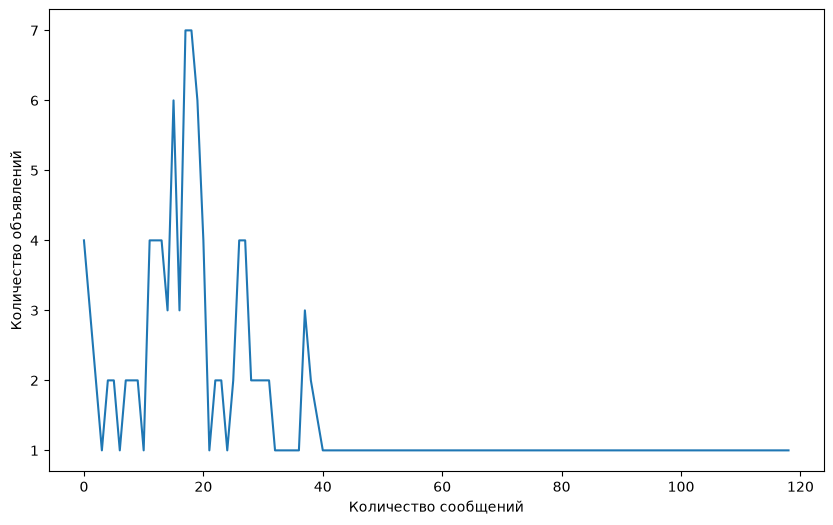

In [21]:
df_messages_total = df['messages_total'].value_counts().sort_index()
plt.figure(figsize=(10, 6))
plt.plot(df_messages_total.index, df_messages_total.values)
plt.xlabel('Количество сообщений')
plt.ylabel('Количество объявлений')
plt.show()

## Анализ is_deal == 0

In [22]:
df = verified_listings_1.copy()